# Helping classes and functions

In [ ]:
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import tensorflow as tnf
import os
from torchvision import models
import torch.nn.functional as F
import torchvision
import gc
import torch.nn as nn

In [ ]:
class MY_Datasets():

    # ---------------------------------------------------------------
    # Helpers
    # ---------------------------------------------------------------

    def background_colour(self, x, channel):
        x = x.clone()
        background = x[:, :, :, channel] == 0
        x[:, :, :, channel][background] += 200
        return x

    def colour_data(self, x, cond, set_1, set_2):
        x_new = torch.where(torch.tensor(cond)[:, None, None, None], set_1, set_2)
        return x_new

    def partial_colour_mask(self, y, min_frac=0.6):
        """ Boolean mask (len == len(y)) marking which samples get the
        class-correlated background colour. For every class, a randomly
        chosen fraction strictly greater than `min_frac` (up to 100%) is
        coloured; the remainder are left as original (grayscale) pixels."""
        y = np.asarray(y).flatten()
        mask = np.zeros(len(y), dtype=bool)
        for c in np.unique(y):
            class_idx = np.where(y == c)[0]
            n = len(class_idx)
            frac = min_frac + np.random.rand() * (1 - min_frac)   # in (min_frac, 1.0]
            n_colour = min(n, max(int(np.ceil(frac * n)), int(np.floor(min_frac * n)) + 1))
            chosen = np.random.choice(class_idx, size=n_colour, replace=False)
            mask[chosen] = True
        return torch.tensor(mask)

    def normalise(self, x):
        """Scale an image tensor/array from [0, 255] to [0, 1] float."""
        return torch.as_tensor(x).float() / 255.0

    def balanced_indices(self, y, num_samples, classes=None):
        """
        Return indices into `y` giving an (as close to) equal number of
        samples per class, up to a total of `num_samples`, shuffled.
        This replaces naive `[:num_samples]` slicing, which can end up
        heavily skewed toward whichever classes appear first in the data.
        """
        y = np.asarray(y).flatten()
        if classes is None:
            classes = np.unique(y)
        n_classes = len(classes)
        per_class = max(1, num_samples // n_classes)

        indices = []
        for c in classes:
            class_idx = np.where(y == c)[0]
            take = min(per_class, len(class_idx))
            chosen = np.random.choice(class_idx, size=take, replace=False)
            indices.append(chosen)

        indices = np.concatenate(indices)
        np.random.shuffle(indices)
        return indices

    def create_loader(self, x, y, BATCH_SIZE, shuffle_bool=False):
        dataset = TensorDataset(x, y)
        loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle_bool)
        return loader

    # ---------------------------------------------------------------
    # MNIST-style coloured dataset
    # ---------------------------------------------------------------

    def create_mnist_dataset(self, dataset, num_train_samples=10000, check_plot=True,
                              save_plot=True, save_dir=".", BATCH_SIZE=64):
        (x_train, y_train), (x_test, y_test) = dataset

        if num_train_samples > len(x_train):
            num_train_samples = len(x_train)
        num_test_samples = int(num_train_samples * 0.25)

        # Class-balanced subsets instead of a naive slice
        train_idx = self.balanced_indices(y_train, num_train_samples)
        test_idx = self.balanced_indices(y_test, num_test_samples)

        x_train = torch.unsqueeze(torch.tensor(x_train), -1).repeat(1, 1, 1, 3)[train_idx]
        y_train = torch.tensor(y_train)[train_idx]
        x_test = torch.unsqueeze(torch.tensor(x_test), -1).repeat(1, 1, 1, 3)[test_idx]
        y_test = torch.tensor(y_test)[test_idx]

        # Coloured train sets
        x_train_red = self.background_colour(x_train, 0)
        x_train_blue = self.background_colour(x_train, 2)
        # Correlated training dataset
        # Correlated training dataset — only >60% of each class gets coloured,
        # the rest stay as the original (grayscale) pixels
        x_train_fully_corr = self.colour_data(x_train, y_train < 5, x_train_red, x_train_blue)
        train_colour_mask = self.partial_colour_mask(y_train, min_frac=0.6)
        x_train_corr = torch.where(train_colour_mask[:, None, None, None], x_train_fully_corr, x_train)
        # Coloured test sets
        x_test_red = self.background_colour(x_test, 0)
        x_test_blue = self.background_colour(x_test, 2)
        # Correlated test dataset
        x_test_corr = self.colour_data(x_test, y_test < 5, x_test_red, x_test_blue)
        # Randomised test dataset
        i = np.random.randint(low=0, high=2, size=y_test.shape)
        x_test_rand = self.colour_data(x_test, i == 1, x_test_red, x_test_blue)
        # Reversed test dataset
        x_test_rev = self.colour_data(x_test, y_test < 5, x_test_blue, x_test_red)

        # --- Normalisation (added, as requested) ---
        x_train = self.normalise(x_train)
        x_train_corr = self.normalise(x_train_corr)
        x_test_corr = self.normalise(x_test_corr)
        x_test_rand = self.normalise(x_test_rand)
        x_test_rev = self.normalise(x_test_rev)

        train_loader_corr = self.create_loader(x_train_corr, y_train, BATCH_SIZE=BATCH_SIZE, shuffle_bool=True)
        train_loader_gray = self.create_loader(x_train, y_train, BATCH_SIZE=BATCH_SIZE, shuffle_bool=True)
        test_loader_corr = self.create_loader(x_test_corr, y_test, BATCH_SIZE=BATCH_SIZE)
        test_loader_rand = self.create_loader(x_test_rand, y_test, BATCH_SIZE=BATCH_SIZE)
        test_loader_rev = self.create_loader(x_test_rev, y_test, BATCH_SIZE=BATCH_SIZE)

        train_loader_dict = {"Correlated": train_loader_corr, "Grayscale": train_loader_gray}
        test_loader_dict = {"Correlated": test_loader_corr, "Random": test_loader_rand, "Reversed": test_loader_rev}

        if check_plot:
            fig, ax = plt.subplots(1, 2)
            ax[0].imshow(x_train[0])
            ax[0].set_title("Original")
            ax[1].imshow(x_train_corr[0])
            ax[1].set_title("Correlated")
            if save_plot:
                plt.savefig(f"{save_dir}/background_change.png")
            plt.show()

        return train_loader_dict, test_loader_dict

    # ---------------------------------------------------------------
    # CIFAR-style ID/OOD dataset (Q3)
    # ---------------------------------------------------------------

    def create_cifar_q3(self, dataset, num_train_samples=10000, check_plot=True,
                         save_plot=True, save_dir=".", BATCH_SIZE=64):
        (x_train, y_train), (x_test, y_test) = dataset

        if num_train_samples > len(x_train):
            num_train_samples = len(x_train)
        test_len = int(0.25 * num_train_samples)

        id_classes = [0, 1, 2, 3, 4]
        ood_classes = list(range(10))

        # Class-balanced in-distribution training subset
        train_idx = self.balanced_indices(y_train, num_train_samples, classes=id_classes)
        subset_x_train = x_train[train_idx]
        subset_y_train = y_train[train_idx]

        # Class-balanced in-distribution test subset
        id_test_idx = self.balanced_indices(y_test, test_len, classes=id_classes)
        x_test_ID = x_test[id_test_idx]
        y_test_ID = y_test[id_test_idx]

        # Class-balanced out-of-distribution test subset (classes never seen in training)
        ood_test_idx = self.balanced_indices(y_test, test_len, classes=ood_classes)
        x_test_OOD = x_test[ood_test_idx]
        y_test_OOD = y_test[ood_test_idx]

        # --- Normalisation (added, as requested) ---
        subset_x_train = self.normalise(subset_x_train)
        x_test_ID = self.normalise(x_test_ID)
        x_test_OOD = self.normalise(x_test_OOD)

        train_loader = self.create_loader(subset_x_train, torch.tensor(subset_y_train).squeeze(-1),
                                           BATCH_SIZE=BATCH_SIZE, shuffle_bool=True)
        test_loader_ID = self.create_loader(x_test_ID, torch.tensor(y_test_ID).squeeze(-1), BATCH_SIZE=BATCH_SIZE)
        test_loader_OOD = self.create_loader(x_test_OOD, torch.tensor(y_test_OOD).squeeze(-1), BATCH_SIZE=BATCH_SIZE)

        return train_loader, test_loader_ID, test_loader_OOD

    # ---------------------------------------------------------------
    # CIFAR-style custom per-class-count dataset (Q4)
    # NOTE: no balancing helper and no normalisation here — `table`
    # already specifies exactly how many samples per class you want.
    # ---------------------------------------------------------------

    def create_cifar_q4(self, table, check_plot=True, save_plot=True, save_dir=".", BATCH_SIZE=64):
        (x_train_init, y_train_init), (x_test_init, y_test_init) = tnf.keras.datasets.cifar10.load_data()

        x_train_list, y_train_list, x_test_list, y_test_list = [], [], [], []
        test_len = 500
        for cls, samples in table.items():
            x_train_list.append(x_train_init[y_train_init.flatten() == cls][:samples])
            y_train_list.append(y_train_init[y_train_init.flatten() == cls][:samples])
            # ASSUMING THE TEST COMES FROM A DIFFERENT DISTRIBUTION AS THE TRAINING DATASET
            x_test_list.append(x_test_init[y_test_init.flatten() == cls][:test_len])
            y_test_list.append(y_test_init[y_test_init.flatten() == cls][:test_len])

        x_train = self.normalise(np.concatenate(x_train_list, axis=0))
        y_train = np.concatenate(y_train_list, axis=0)
        x_test = np.concatenate(x_test_list, axis=0)
        y_test = np.concatenate(y_test_list, axis=0)

        train_loader = self.create_loader(torch.tensor(x_train), torch.tensor(y_train).squeeze(-1),
                                           BATCH_SIZE=BATCH_SIZE, shuffle_bool=True)
        test_loader = self.create_loader(torch.tensor(x_test), torch.tensor(y_test).squeeze(-1),
                                          BATCH_SIZE=BATCH_SIZE, shuffle_bool=True)
        return train_loader, test_loader

In [ ]:


def set_seed(SEED):
    import numpy as np
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

def create_model(name, save_dir, num_classes=10):
    if name == "resnet50":
        model = models.resnet50(weights=None)
        # Adapt ResNet fc layer to num_classes
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        SAVE_PTH = f"{save_dir}/resnet50.pth"
    elif name == "vit":
        model = models.vit_b_16(weights=None)
        # Adapt ViT classification head to num_classes
        model.heads.head = nn.Linear(model.heads.head.in_features, num_classes)
        SAVE_PTH = f"{save_dir}/vit.pth"
    else:
        raise ValueError(f"Unknown model name: {name}")

    return model, SAVE_PTH

def get_num_classes_from_loader(loader, table=None):
    if table is not None:
        return len(table)
    try:
        max_label = int(loader.dataset.tensors[1].max().item())
        return max_label + 1
    except (AttributeError, IndexError):
        return 10

def train(name, train_loader, save_dir, load_state=True, epochs=1, seed=42, wtd_loss=False, table=None):
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    set_seed(seed)
    os.makedirs(save_dir, exist_ok=True)

    num_classes = get_num_classes_from_loader(train_loader, table)
    model, SAVE_PTH = create_model(name, save_dir, num_classes=num_classes)

    # 1. MOVE MODEL TO DEVICE FIRST (Fixes Optimizer CUDA/CPU mismatch)
    model = model.to(DEVICE)

    # 2. LOAD STATE DICT BEFORE DATAPARALLEL
    if os.path.exists(SAVE_PTH) and load_state:
        checkpoint = torch.load(SAVE_PTH, map_location=DEVICE)
        model.load_state_dict(checkpoint['state_dict'])

    # 3. WRAP DATAPARALLEL IF MULTI-GPU
    if torch.cuda.device_count() > 1 and DEVICE == "cuda":
        print(f"Using {torch.cuda.device_count()} GPUs!")
        model = nn.DataParallel(model)

    # 4. INSTANTIATE OPTIMIZER AFTER MODEL IS ON CUDA
    optimiser = torch.optim.Adam(model.parameters(), lr=0.001)

    if os.path.exists(SAVE_PTH) and load_state and 'optimizer' in checkpoint:
        optimiser.load_state_dict(checkpoint['optimizer'])

    # Setup Loss Function
    if wtd_loss and table is not None:
        num_classes = len(table)
        total_samples = sum(table.values())
        class_counts = [table[i] for i in list(table.keys())]
        class_weights = [total_samples / (num_classes * count) for count in class_counts]
        weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(DEVICE)
        loss_fn = nn.CrossEntropyLoss(weight=weights_tensor)
    else:
        loss_fn = nn.CrossEntropyLoss()

    for epoch in range(epochs):
        model.train()
        loss_total = 0.0
        for x, y in train_loader:
            optimiser.zero_grad()

            # Format inputs and targets properly
            x = x.permute(0, 3, 1, 2).float()
            if x.shape[-2:] != (224, 224):
                x = F.interpolate(x, size=(224, 224), mode='nearest')

            x = x.to(DEVICE)
            y = y.to(DEVICE).squeeze().long()  # Guarantees correct shape and 64-bit int type

            pred = model(x)
            batch_loss = loss_fn(pred, y)
            batch_loss.backward()
            optimiser.step()

            # Accumulate purely as python scalar to prevent computational graph memory leakage
            loss_total += batch_loss.item()

        loss_total /= len(train_loader)
        print(f"Epoch {epoch} loss {loss_total:.4f}")
        if loss_total < 1e-3:
            break

    # Save state
    model_state = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
    checkpoint = {
        "epoch": epoch,
        "final_loss": loss_total,
        "state_dict": model_state,
        "optimizer": optimiser.state_dict(),
    }
    torch.save(checkpoint, SAVE_PTH)
    print(f"Model {name} trained for {epochs} epochs with final loss {loss_total:.4f}; Saved to {SAVE_PTH}")

    # --- COMPLETE GPU MEMORY PURGE ---
    model.cpu()
    del model, optimiser, loss_fn
    gc.collect()
    torch.cuda.empty_cache()


def test(name, save_dir, test_loader_dict, load_state=True, report_all=False, table=None):
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    set_seed(42)
    first_loader = next(iter(test_loader_dict.values()))
    num_classes = get_num_classes_from_loader(first_loader, table)
    model, SAVE_PTH = create_model(name, save_dir, num_classes=num_classes)

    if os.path.exists(SAVE_PTH) and load_state:
        checkpoint = torch.load(SAVE_PTH, map_location=DEVICE)
        model.load_state_dict(checkpoint['state_dict'])

    model = model.to(DEVICE)
    if torch.cuda.device_count() > 1 and DEVICE == "cuda":
        print(f"Testing on {torch.cuda.device_count()} GPUs!")
        model = nn.DataParallel(model)

    model.eval()
    loss_fn = nn.CrossEntropyLoss()
    stats = {}
    with torch.no_grad():
        for loader_name, test_loader in test_loader_dict.items():
            correct = 0
            total = 0
            class_correct = None
            class_total = None
            for x, y in test_loader:
                x = x.permute(0, 3, 1, 2).float()
                if x.shape[-2:] != (224, 224):
                    x = F.interpolate(x, size=(224, 224), mode='nearest')

                x = x.to(DEVICE)
                y = y.to(DEVICE).squeeze().long()
                pred = model(x)
                preds = pred.argmax(dim=1)
                correct += (preds == y).sum().item()
                total += y.size(0)
                if report_all:
                    curr_num_classes = max(
                        pred.size(1) if pred.ndim > 1 else 0,
                        len(table) if table is not None else 0,
                        int(y.max().item()) + 1)
                    if class_correct is None:
                        class_correct = torch.zeros(curr_num_classes, device=DEVICE)
                        class_total = torch.zeros(curr_num_classes, device=DEVICE)
                    elif curr_num_classes > class_correct.size(0):
                        pad_size = curr_num_classes - class_correct.size(0)
                        class_correct = F.pad(class_correct, (0, pad_size))
                        class_total = F.pad(class_total, (0, pad_size))
                    curr_len = class_correct.size(0)
                    is_correct = (preds == y).float()
                    class_correct += torch.bincount(y[is_correct == 1], minlength=curr_len)[:curr_len]
                    class_total += torch.bincount(y, minlength=curr_len)[:curr_len]

            accuracy = correct / total
            print(f"On {loader_name}: Model {name} test accuracy {accuracy:.4f}")
            if report_all:
                nonzero_mask = class_total > 0
                per_class_acc = torch.zeros_like(class_total)
                per_class_acc[nonzero_mask] = class_correct[nonzero_mask] / class_total[nonzero_mask]
                balanced_acc = per_class_acc[nonzero_mask].mean().item() if nonzero_mask.any() else 0.0
                worst_class_acc = per_class_acc[nonzero_mask].min().item() if nonzero_mask.any() else 0.0
                per_class_acc_dict = {i: acc.item() for i, acc in enumerate(per_class_acc)}
                print(f"  Balanced Accuracy:    {balanced_acc:.4f}")
                print(f"  Worst-Class Accuracy: {worst_class_acc:.4f}")
                print(f"  Per-Class Accuracy:   {per_class_acc_dict}")
                stats[loader_name] = {
                    "accuracy": accuracy,
                    "per_class_accuracy": per_class_acc_dict,
                    "balanced_accuracy": balanced_acc,
                    "worst_class_accuracy": worst_class_acc
                }
            else:
                stats[loader_name] = accuracy

    os.makedirs(save_dir, exist_ok=True)
    torch.save(stats, f"{save_dir}/{name}_test_scores.pt")

    # --- COMPLETE GPU MEMORY PURGE ---
    model.cpu()
    del model, loss_fn
    gc.collect()
    torch.cuda.empty_cache()

# Q1
 Detecting Color Bias in Classification. Modify the MNIST dataset so that the
background/foreground color is correlated with the digit label during training. For
example:
1. Digits 0–4 → predominantly one color
2. Digits 5–9 → predominantly another color
<br>
<b> Task-1:</b> Train at least 2 CNN/ViTs/Foundation Models on this dataset and report
test accuracy when:
color correlation is maintained,
color is randomized or removed,
color-label correlation is reversed.
<br>
<b>Task-2: </b> Train a second model using grayscale images.
Compare the two models.
Investigate whether the model is relying on digit shape or color.

STARTING
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/tmp/ipykernel_23/3207586910.py:14: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x_new = torch.where(torch.tensor(cond)[:, None, None, None], set_1, set_2)


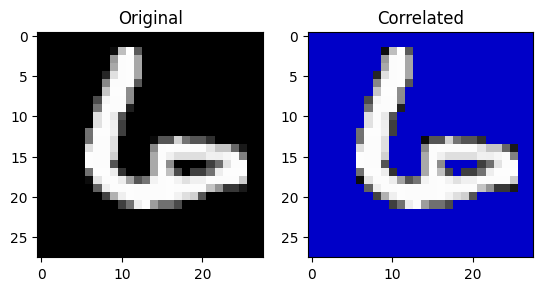

Training on Correlated dataset
--------------------------------------------------
Training resnet50 model
Using 2 GPUs!
Epoch 0 loss 0.4152
Epoch 1 loss 0.1049
Epoch 2 loss 0.0718
Epoch 3 loss 0.0569
Epoch 4 loss 0.0437
Epoch 5 loss 0.0418
Epoch 6 loss 0.0505
Epoch 7 loss 0.0487
Epoch 8 loss 0.0246
Epoch 9 loss 0.0300
Epoch 10 loss 0.0223
Epoch 11 loss 0.0375
Epoch 12 loss 0.0704
Epoch 13 loss 0.0204
Epoch 14 loss 0.0136
Epoch 15 loss 0.0150
Epoch 16 loss 0.0181
Epoch 17 loss 0.0226
Epoch 18 loss 0.0405
Epoch 19 loss 0.0321
Model resnet50 trained for 20 epochs with final loss 0.0321; Saved to ./Q1/Correlated/resnet50.pth
--------------------------------------------------
Testing accuracy of resnet50 model
Testing on 2 GPUs!
On Correlated: Model resnet50 test accuracy 0.9820
On Random: Model resnet50 test accuracy 0.6520
On Reversed: Model resnet50 test accuracy 0.3144
--------------------------------------------------
Training vit model
Using 2 GPUs!
Epoch 0 loss 1.9205
Epoch 1 loss 1.

In [ ]:
print("STARTING")
model_list = ["resnet50", "vit"]
EPOCHS = 20
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 64
parent_dir = "./Q1"
if not os.path.exists(parent_dir):
    os.mkdir(parent_dir)
set_seed(42)
train_loader_dict, test_loader_dict = MY_Datasets().create_mnist_dataset(tnf.keras.datasets.mnist.load_data(), BATCH_SIZE=BATCH_SIZE)

for loader_name, loader in train_loader_dict.items():
  print(f"Training on {loader_name} dataset")
  save_dir = f"{parent_dir}/{loader_name}"
  if loader_name == "Grayscale": model_list = ["resnet50"] #Question only states one model on grayscale
  for name in model_list:
    set_seed(42)
    print("-"*50)
    print(f"Training {name} model")
    train(name, epochs = EPOCHS, train_loader = loader, save_dir= save_dir)
    print("-"*50)
    print(f"Testing accuracy of {name} model")
    test(name,save_dir= save_dir, test_loader_dict=test_loader_dict)
    print("="*50)
del loader
gc.collect()
torch.cuda.empty_cache()


# Q3

When Should an AI Model Say “I Don’t Know”?. Train a classifier on a
subset of classes from a dataset such as CIFAR-10. For example:
1. Training classes: airplane, automobile, bird, cat, deer
2. Unknown/OOD classes: dog, frog, horse, ship, truck
Task-1: Train at least 2 CNN/ViTs/Foundation Models on this dataset and report
test accuracy when:
First evaluate the model normally with and without OOD classes,
Task-2: Then implement a simple confidence-based OOD detector.
If maximum softmax probability < threshold − > reject / “I don’t know.” Evaluate
the system for several thresholds.
Plot confidence distributions for ID and OOD samples.
Performance Metrics: Calculate: ID accuracy, OOD detection accuracy, FPR/FNR,
AUROC. Study the effect of changing the confidence threshold. Show examples
where the model is highly confident but wrong.

In [ ]:
from sklearn.metrics import roc_auc_score
print("STARTING")
model_list = ["resnet50", "vit"]
EPOCHS = 20
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
parent_dir = "./Q3"
if not os.path.exists(parent_dir):
    os.mkdir(parent_dir)
set_seed(42)
train_loader, test_loader_ID, test_loader_OOD = MY_Datasets().create_cifar_q3(tnf.keras.datasets.cifar10.load_data(), BATCH_SIZE=64)
test_loader_dict = {"Test set without OOD classes": test_loader_ID, "Test set with OOD classes": test_loader_OOD}

STARTING
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2114s 12us/step


TASK 1: Training models on dataset with classes 0-4
Training resnet50 model
Using 2 GPUs!
Epoch 0 loss 1.2441
Epoch 1 loss 1.0184
Epoch 2 loss 0.9214
Epoch 3 loss 0.8316
Epoch 4 loss 0.7492
Epoch 5 loss 0.6807
Epoch 6 loss 0.6239
Epoch 7 loss 0.5669
Epoch 8 loss 0.4967
Epoch 9 loss 0.4572
Epoch 10 loss 0.3938
Epoch 11 loss 0.3367
Epoch 12 loss 0.3058
Epoch 13 loss 0.2579
Epoch 14 loss 0.2248
Epoch 15 loss 0.1860
Epoch 16 loss 0.1567
Epoch 17 loss 0.1381
Epoch 18 loss 0.1610
Epoch 19 loss 0.1214
Model resnet50 trained for 20 epochs with final loss 0.1214; Saved to ./Q3/resnet50.pth
Testing accuracy of resnet50 model
Testing on 2 GPUs!
On Test set without OOD classes: Model resnet50 test accuracy 0.7968
On Test set with OOD classes: Model resnet50 test accuracy 0.4000
Training vit model
Using 2 GPUs!
Epoch 0 loss 1.8223
Epoch 1 loss 1.6469
Epoch 2 loss 1.6333
Epoch 3 loss 1.6339
Epoch 4 loss 1.6427
Epoch 5 loss 1.6345
Epoch 6 loss 1.6331
Epoch 7 loss 1.6139
Epoch 8 loss 1.6048
Epoch 9 lo

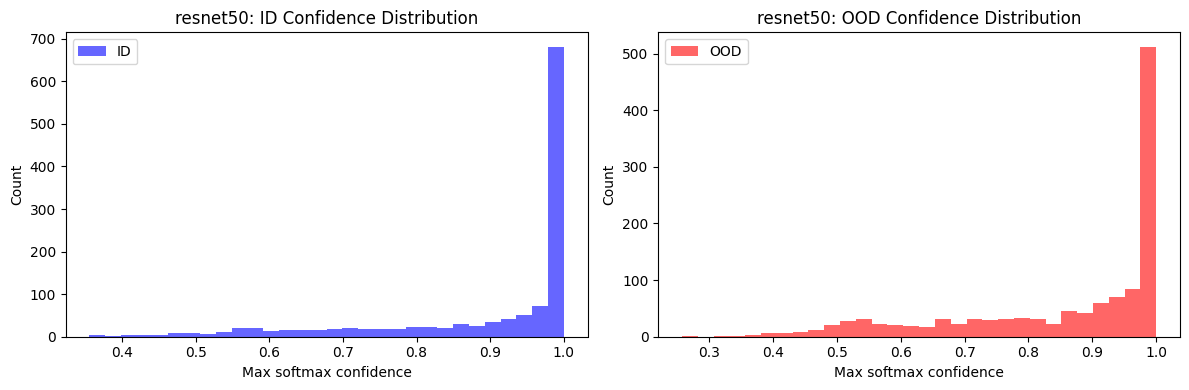

resnet50 OOD-detection AUROC: 0.6025
  thresh=0.3: ID acc=0.778 OOD-det acc=0.501 FPR=0.998 FNR=0.000
  thresh=0.5: ID acc=0.791 OOD-det acc=0.510 FPR=0.956 FNR=0.025
  thresh=0.7: ID acc=0.838 OOD-det acc=0.533 FPR=0.796 FNR=0.138
  thresh=0.9: ID acc=0.903 OOD-det acc=0.558 FPR=0.582 FNR=0.302
resnet50: 85 confident-but-wrong ID examples (showing up to 10)


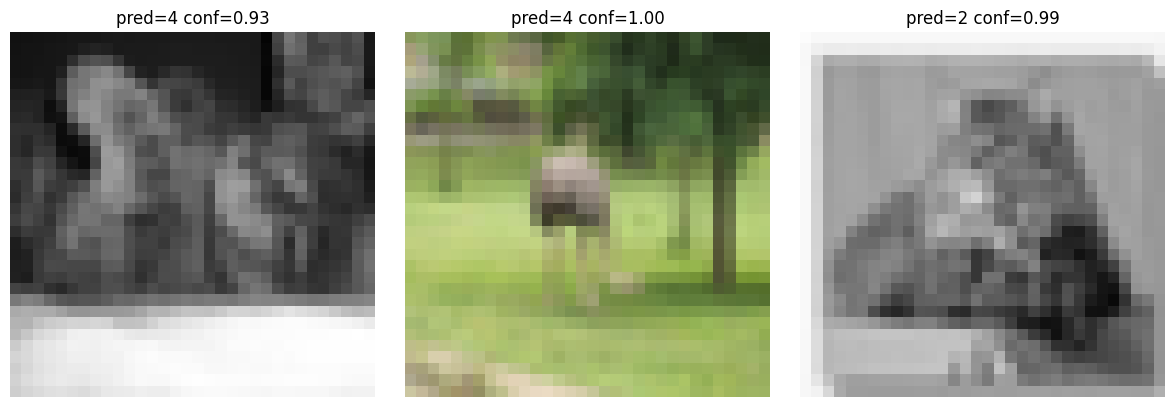

Loaded checkpoint from ./Q3/vit.pth
Evaluating model: vit


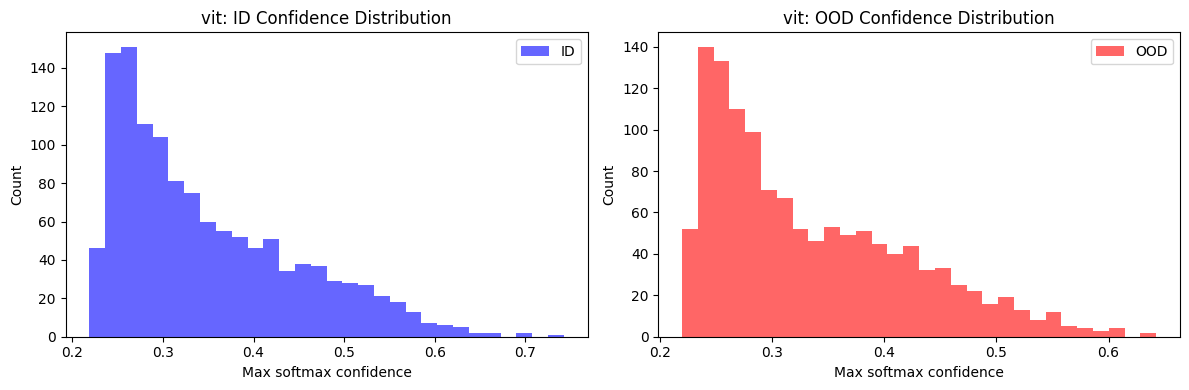

vit OOD-detection AUROC: 0.5386
  thresh=0.3: ID acc=0.379 OOD-det acc=0.524 FPR=0.530 FNR=0.422
  thresh=0.5: ID acc=0.488 OOD-det acc=0.522 FPR=0.058 FNR=0.898
  thresh=0.7: ID acc=0.000 OOD-det acc=0.501 FPR=0.000 FNR=0.998
  thresh=0.9: ID acc=0.000 OOD-det acc=0.500 FPR=0.000 FNR=1.000
vit: 0 confident-but-wrong ID examples (showing up to 0)


In [ ]:
print("TASK 1: Training models on dataset with classes 0-4")
save_dir = parent_dir
for name in model_list:
  set_seed(42)
  print("="*50)
  print(f"Training {name} model")
  train(name, epochs = EPOCHS, train_loader = train_loader, save_dir= save_dir)
  print(f"Testing accuracy of {name} model")
  test(name,save_dir= save_dir, test_loader_dict = test_loader_dict)

print("="*50)
print("TASK 2: Starting with thresholding")
# TASK 2: following function was taken from Claude (Anthropic) and modified
"""This function was taken from claude, then modified by me for my own functions e.g. i do not use function prep() but claude did"""
def get_confidences_and_labels(model, loader, device=DEVICE, wrong_conf_thresh=0.9, max_examples=10):
    confs, is_id_list, correct_list, preds_list = [], [], [], []
    hard_examples = []  # only stores (image, pred, conf) for confidently-wrong ID samples
    ID_CLASSES = [0, 1, 2, 3, 4]
    model.eval()
    with torch.no_grad():
        for x, y in loader:
            # Format tensor for model input (N, C, 224, 224)
            if x.shape[-2:] != (224, 224):
                x_in = x.permute(0, 3, 1, 2) if x.shape[-1] == 3 else x
                x_in = F.interpolate(x_in.float(), size=(224, 224), mode='bilinear', align_corners=False)
            else: x_in = x.float()
            x_in = x_in.to(device)
            probs = F.softmax(model(x_in), dim=1)
            conf, pred = probs.max(1)
            conf_np = conf.cpu().numpy()
            pred_np = pred.cpu().numpy()
            y_np = y.numpy()
            is_id = np.isin(y_np, ID_CLASSES)
            correct = (pred_np == y_np) & is_id
            confs.append(conf_np)
            is_id_list.append(is_id)
            correct_list.append(correct)
            preds_list.append(pred_np)
            # Only pull out and keep the handful of images we might actually plot
            if len(hard_examples) < max_examples:
                wrong_mask = (~correct) & is_id & (conf_np > wrong_conf_thresh)
                for i in np.where(wrong_mask)[0]:
                    if len(hard_examples) >= max_examples:
                        break
                    hard_examples.append((x[i].numpy(), pred_np[i], conf_np[i]))

    return (np.concatenate(confs), np.concatenate(is_id_list),
            np.concatenate(correct_list), np.concatenate(preds_list), hard_examples)
loader = test_loader_dict["Test set with OOD classes"]

for name in model_list:
    model, SAVE_PTH = create_model(name, save_dir=save_dir, num_classes = 5)
    if os.path.exists(SAVE_PTH):
        checkpoint = torch.load(SAVE_PTH, map_location=DEVICE)
        model.load_state_dict(checkpoint['state_dict'])
        print(f"Loaded checkpoint from {SAVE_PTH}")
    else:
        raise FileNotFoundError(f"No checkpoint found at {SAVE_PTH}")

    model = model.to(DEVICE)
    if torch.cuda.device_count() > 1 and DEVICE == "cuda":
        model = torch.nn.DataParallel(model)

    print("="*50)
    print(f"Evaluating model: {name}")
    conf, is_id, correct, pred, hard_examples = get_confidences_and_labels(model, loader, device=DEVICE)
    # Plot confidence distributions
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].hist(conf[is_id], bins=30, alpha=0.6, label="ID", color="blue")
    ax[0].set_xlabel("Max softmax confidence")
    ax[0].set_ylabel("Count")
    ax[0].legend()
    ax[0].set_title(f"{name}: ID Confidence Distribution")
    ax[1].hist(conf[~is_id], bins=30, alpha=0.6, label="OOD", color="red")
    ax[1].set_xlabel("Max softmax confidence")
    ax[1].set_ylabel("Count")
    ax[1].legend()
    ax[1].set_title(f"{name}: OOD Confidence Distribution")
    plt.tight_layout()
    plt.show()
    # AUROC
    auroc = roc_auc_score(is_id.astype(int), conf)
    print(f"{name} OOD-detection AUROC: {auroc:.4f}")
    # Threshold sweep
    for thresh in [0.3, 0.5, 0.7, 0.9]:
        pred_id = conf >= thresh
        id_acc = correct[is_id & pred_id].sum() / max(pred_id[is_id].sum(), 1)
        fpr = ((~is_id) & pred_id).sum() / max((~is_id).sum(), 1)
        fnr = (is_id & ~pred_id).sum() / max(is_id.sum(), 1)
        ood_det_acc = (is_id == pred_id).mean()
        print(f"  thresh={thresh}: ID acc={id_acc:.3f} OOD-det acc={ood_det_acc:.3f} FPR={fpr:.3f} FNR={fnr:.3f}")

    # Total count (from full arrays), even though we only kept `max_examples` images
    total_wrong_confident = ((~correct) & is_id & (conf > 0.9)).sum()
    print(f"{name}: {total_wrong_confident} confident-but-wrong ID examples (showing up to {len(hard_examples)})")

    if hard_examples:
        num_to_plot = min(3, len(hard_examples))
        fig, ax = plt.subplots(1, num_to_plot, figsize=(4 * num_to_plot, 4))
        if num_to_plot == 1:
            ax = [ax]
        for i, (img, p, c) in enumerate(hard_examples[:num_to_plot]):
            if img.shape[0] == 3:
                img = np.transpose(img, (1, 2, 0))
            if img.max() <= 1.0:
                img = (img * 255.0).clip(0, 255).astype(np.uint8)
            else:
                img = img.astype(np.uint8)
            ax[i].imshow(img)
            ax[i].set_title(f"pred={p} conf={c:.2f}")
            ax[i].axis("off")
        plt.tight_layout()
        plt.savefig(f"{save_dir}/{name}_confident_wrong.png")
        plt.show()

    del model, conf, is_id, correct, pred, hard_examples
    torch.cuda.empty_cache()
    gc.collect()

# Q4
The Long Tail Problem: What Happens to Rare Classes?. Construct an
imbalanced classification dataset with a long-tailed class distribution as shown in
Table 1.<br><br>
Task-1: Train at least 2 CNN/ViTs/Foundation Models on this dataset and report
test accuracy when:
Performance Metrics: Do not report only overall accuracy. Instead calculate: (i)
Per-class accuracy, (ii) Balanced accuracy, (iii) Worst-class accuracy,<br><br>
Task-2: Then try one intervention: (i) Oversampling, (ii) Class-weighted loss, (iii)
Focal loss
Performance Metrics: Compare the results.
Key question: If 95% of the data is classified correctly but the model consistently
fails on rare cases, is the AI system responsible or reliable?

In [ ]:
table = {0:10000, 1: 5000, 3: 2500 , 4:1000, 5: 500 , 6:100 , 2:50}
print("STARTING")
set_seed(42)
train_loader, test_loader = MY_Datasets().create_cifar_q4(table, BATCH_SIZE=64)
test_loader_dict = {"Test set": test_loader}
# TASK 1
model_list = ["resnet50", "vit"]
EPOCHS = 20
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
parent_dir = "./Q4"
if not os.path.exists(parent_dir):
    os.mkdir(parent_dir)

test_loader_dict = {"imbalanced_test": test_loader}
print("TASK 1: Training models on dataset with following samples")
print(table)
save_dir = f"{parent_dir}/unweighted_loss"
for name in model_list:
  set_seed(42)
  print("="*50)
  print(f"Training {name} model")
  train(name, epochs = EPOCHS, train_loader = train_loader, save_dir= save_dir)
  print(f"Testing accuracy of {name} model")
  test(name,save_dir= save_dir, test_loader_dict = test_loader_dict, report_all=True, table = table)

print("TASK 2: Training models with class weighted loss")
save_dir = f"{parent_dir}/weighted_loss"
for name in model_list:
  set_seed(42)
  print("="*50)
  print(f"Training {name} model")
  train(name, epochs = EPOCHS, train_loader = train_loader,  save_dir= save_dir, wtd_loss=True, table = table)
  print(f"Testing accuracy of {name} model")
  test(name,save_dir= save_dir, test_loader_dict = test_loader_dict, report_all=True, table = table)


STARTING


/tmp/ipykernel_23/3207586910.py:200: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  train_loader = self.create_loader(torch.tensor(x_train), torch.tensor(y_train).squeeze(-1),


TASK 1: Training models on dataset with following samples
{0: 10000, 1: 5000, 3: 2500, 4: 1000, 5: 500, 6: 100, 2: 50}
Training resnet50 model
Using 2 GPUs!
Epoch 0 loss 0.9186
Epoch 1 loss 0.6967
Epoch 2 loss 0.5944
Epoch 3 loss 0.5445
Epoch 4 loss 0.5043
Epoch 5 loss 0.4753
Epoch 6 loss 0.4369
Epoch 7 loss 0.3830
Epoch 8 loss 0.3569
Epoch 9 loss 0.3189
Epoch 10 loss 0.3019
Epoch 11 loss 0.2733
Epoch 12 loss 0.3598
Epoch 13 loss 0.3206
Epoch 14 loss 0.2813
Epoch 15 loss 0.1857
Epoch 16 loss 0.1801
Epoch 17 loss 0.1476
Epoch 18 loss 0.1516
Epoch 19 loss 0.1091
Model resnet50 trained for 20 epochs with final loss 0.1091; Saved to ./Q4/unweighted_loss/resnet50.pth
Testing accuracy of resnet50 model
Testing on 2 GPUs!
On imbalanced_test: Model resnet50 test accuracy 0.1429
  Balanced Accuracy:    0.1429
  Worst-Class Accuracy: 0.0000
  Per-Class Accuracy:   {0: 0.0, 1: 1.0, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.0, 6: 0.0}
Training vit model
Using 2 GPUs!
Epoch 0 loss 1.5904
Epoch 1 loss 1.4340
Epo